# Heart Disease UCI: Exploratory Data Analysis & Diagnostic Profiling

**Course:** AIMLCZG523 - Machine Learning Operations (MLOps)  
**Institution:** BITS Pilani  
**Dataset:** Heart Disease UCI (Cleveland Clinic Foundation Variant)  
**Objective:** End-to-end exploratory data analysis, clinical schema validation, data quality checks, and diagnostic pattern identification for cardiovascular risk prediction.

---

## 1. Dataset Overview & Attribution

The Cleveland Clinic Heart Disease dataset is the foundational benchmark dataset in cardiovascular machine learning research. It was collected by:
- **Robert Detrano, M.D., Ph.D.** (Long Beach V.A. Medical Center and Cleveland Clinic Foundation)
- **Matthias Pfisterer, M.D.** (University Hospital, Basel, Switzerland)
- **William Steinbrunn, M.D.** (University Hospital, Zurich, Switzerland)
- **Andras Janosi, M.D.** (Hungarian Institute of Cardiology, Budapest)

- **Donor:** David W. Aha (aha@ics.uci.edu), UCI Machine Learning Repository.
- **License:** Creative Commons Attribution 4.0 International (CC BY 4.0).
- **Official Repository URL:** https://archive.ics.uci.edu/dataset/45/heart+disease


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Path resolution
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = BASE_DIR / "data" / "processed" / "heart_cleaned.csv"
print(f"Data source: {DATA_PATH.resolve()}")
print(f"Output figures: {FIGURES_DIR.resolve()}")

Data source: /Users/divya.kulkarni/Documents/personalProject/MLOpsAss1/data/processed/heart_cleaned.csv
Output figures: /Users/divya.kulkarni/Documents/personalProject/MLOpsAss1/reports/figures


## 2. Clinical Schema Definition & Head Preview

The dataset contains 14 clinical attributes:
- `age`: Patient age in years (numerical).
- `sex`: Biological sex (1 = Male, 0 = Female) (binary).
- `cp`: Chest pain type (1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic) (nominal).
- `trestbps`: Resting systolic blood pressure on hospital admission in mm Hg (numerical).
- `chol`: Serum cholesterol in mg/dl (numerical).
- `fbs`: Fasting blood sugar > 120 mg/dl (1 = True, 0 = False) (binary).
- `restecg`: Resting electrocardiographic results (0 = Normal, 1 = ST-T wave abnormality, 2 = LVH) (nominal).
- `thalach`: Maximum heart rate achieved during exercise treadmill testing (numerical).
- `exang`: Exercise-induced angina (1 = Yes, 0 = No) (binary).
- `oldpeak`: ST depression induced by exercise relative to rest (continuous).
- `slope`: Peak exercise ST segment slope (1 = Upsloping, 2 = Flat, 3 = Downsloping) (ordinal).
- `ca`: Major coronary vessels colored by fluoroscopy (0-3) (ordinal).
- `thal`: Thalassemia scintigraphy (3 = Normal, 6 = Fixed defect, 7 = Reversible defect) (nominal).
- `target`: Diagnosis (0 = Absence; 1 = Presence of angiographic disease > 50% narrowing).


In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)

Dataset Dimensions: 303 rows, 15 columns
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  target  target_raw
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3    3.0  0.0   6.0       0           0
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5    2.0  3.0   3.0       1           2
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6    2.0  2.0   7.0       1           1
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5    3.0  0.0   3.0       0           0
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4    1.0  0.0   3.0       0           0


## 3. Parametric Summary Statistics & Frequency Profiles

In [3]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
print("=== Numerical Feature Statistics ===")
print(df[num_cols].describe().T)

print("\n=== Categorical Feature Distributions ===")
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
for c in cat_cols:
    print(f"{c.upper()}: {dict(df[c].value_counts(dropna=False))}")

=== Numerical Feature Statistics ===
          count        mean        std    min    25%    50%    75%    max
age       303.0   54.438944   9.038662   29.0   48.0   56.0   61.0   77.0
trestbps  303.0  131.689769  17.599748   94.0  120.0  130.0  140.0  200.0
chol      303.0  246.693069  51.776918  126.0  211.0  241.0  275.0  564.0
thalach   303.0  149.607261  22.875003   71.0  133.5  153.0  166.0  202.0
oldpeak   303.0    1.039604   1.161075    0.0    0.0    0.8    1.6    6.2

=== Categorical Feature Distributions ===
SEX: {1.0: 206, 0.0: 97}
CP: {4.0: 144, 3.0: 86, 2.0: 50, 1.0: 23}
FBS: {0.0: 258, 1.0: 45}
RESTECG: {0.0: 151, 2.0: 148, 1.0: 4}
EXANG: {0.0: 204, 1.0: 99}
SLOPE: {1.0: 142, 2.0: 140, 3.0: 21}
CA: {0.0: 176, 1.0: 65, 2.0: 38, 3.0: 20, nan: 4}
THAL: {3.0: 166, 7.0: 117, 6.0: 18, nan: 2}


## 4. Data Quality, Missing Values, and Duplicate Records Analysis

In [4]:
missing_counts = df.isnull().sum()
duplicates = df.duplicated().sum()
print(f"Total Rows: {len(df)}")
print(f"Duplicate Rows: {duplicates}")
print("\nMissing Values Breakdown:")
for col, cnt in missing_counts.items():
    if cnt > 0:
        print(f" - {col}: {cnt} missing values ({cnt/len(df)*100:.2f}%)")
if missing_counts.sum() == 0:
    print(" - None")

Total Rows: 303
Duplicate Rows: 0

Missing Values Breakdown:
 - ca: 4 missing values (1.32%)
 - thal: 2 missing values (0.66%)


## 5. Target Class Distribution: Multi-Category to Binary Mapping

The raw clinical recording registers target values from 0 to 4:
- `0`: Angiographic diameter narrowing < 50% (absence of clinically significant coronary disease).
- `1, 2, 3, 4`: Progressive stages of vessel narrowing > 50% (mild, moderate, severe, critical narrowing).

Following clinical cardiology benchmarks and assignment requirements, we formulate this as a **binary risk classification task**:
- **Class 0 (Negative / Absence):** Low cardiovascular event risk (164 patients, 54.1%).
- **Class 1 (Positive / Presence):** Elevated cardiovascular event risk warranting clinical therapy (139 patients, 45.9%).


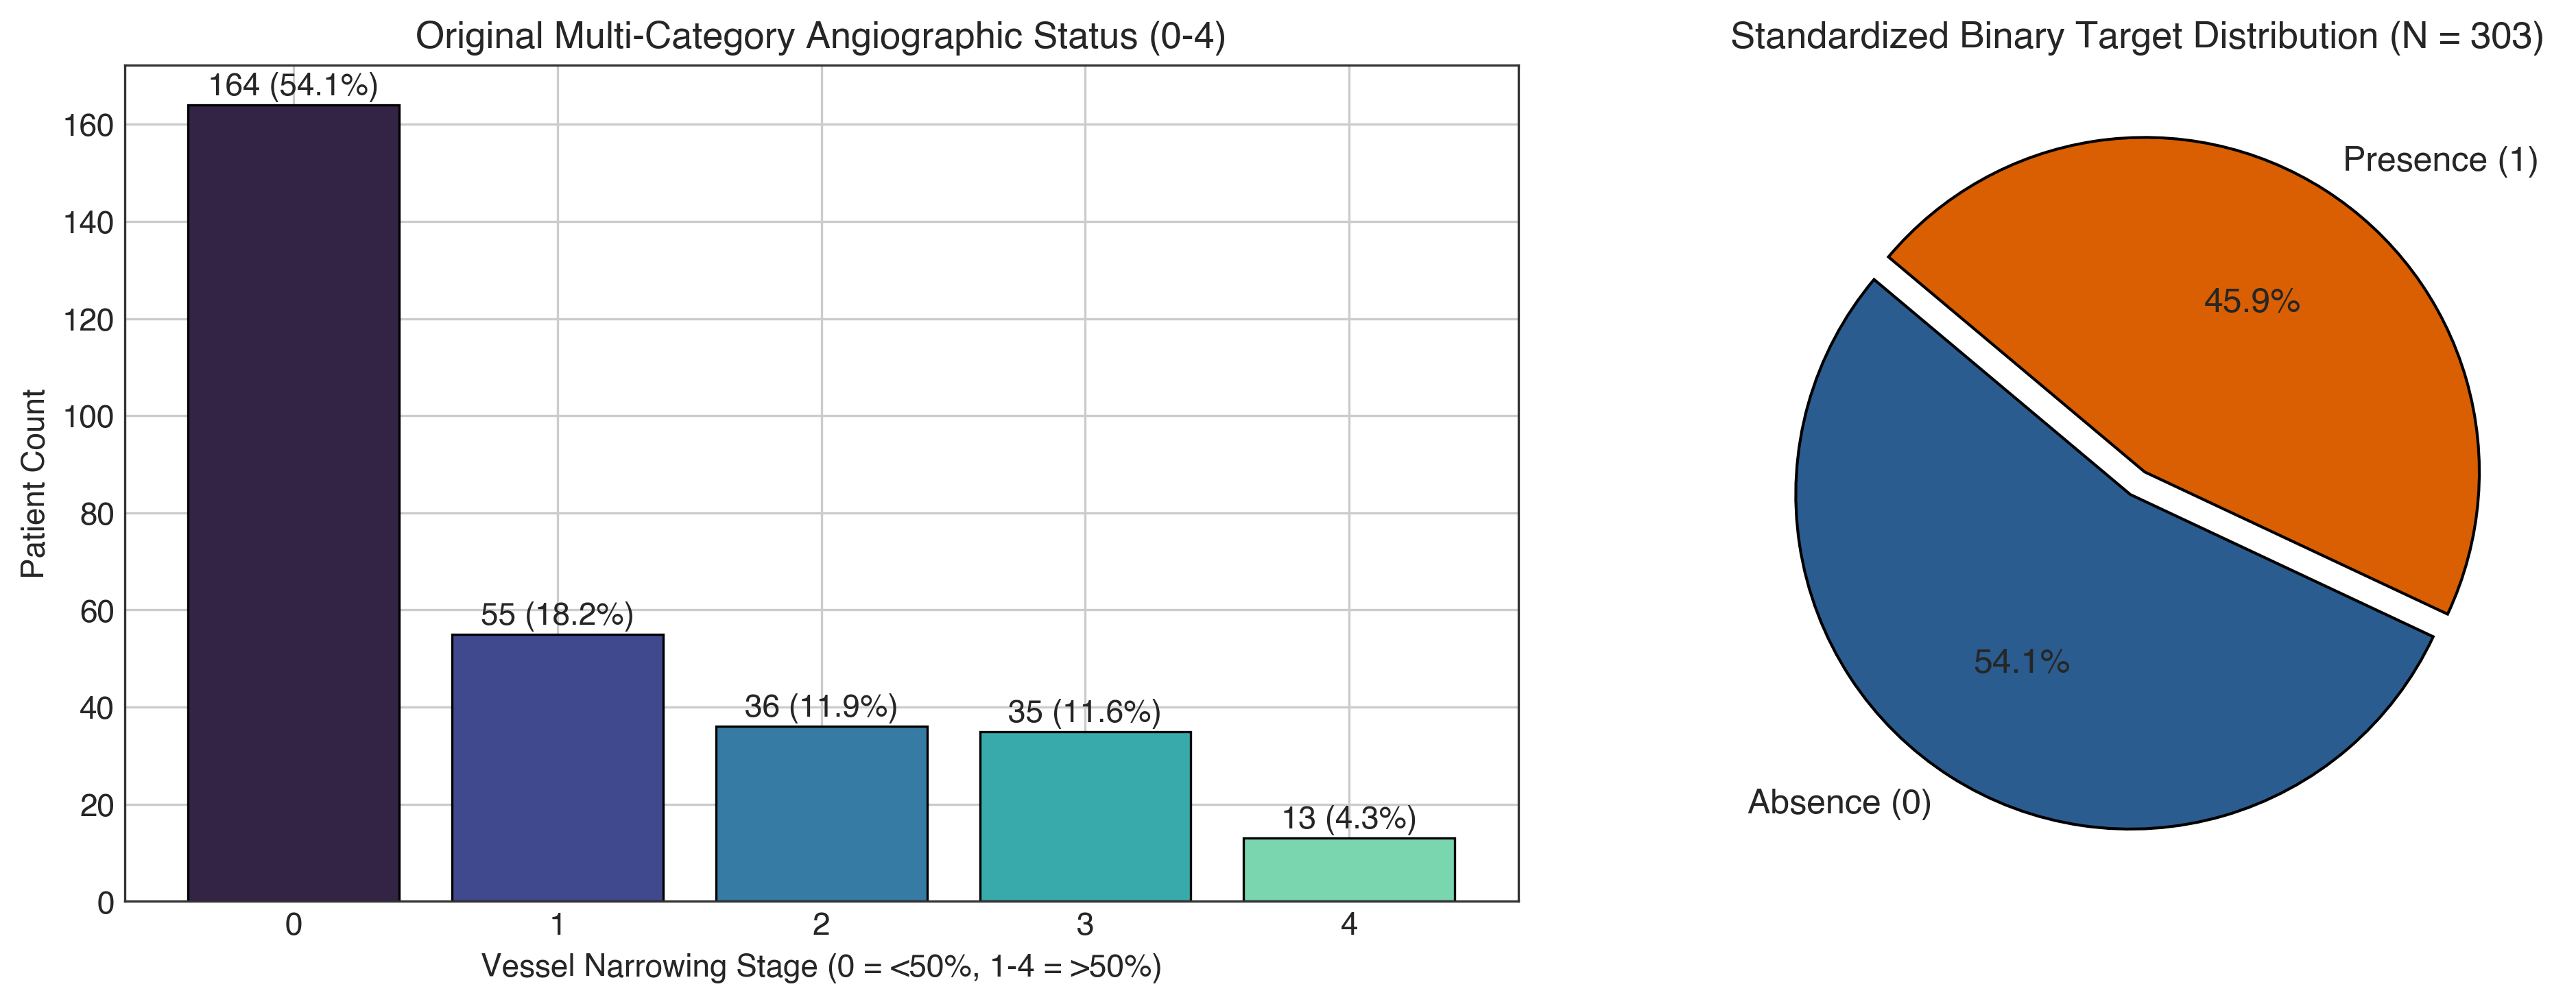

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Raw multi-class
raw_counts = df['target_raw'].value_counts().sort_index()
palette_raw = sns.color_palette("mako", len(raw_counts))
axes[0].bar(raw_counts.index.astype(str), raw_counts.values, color=palette_raw, edgecolor='black', linewidth=0.8)
axes[0].set_title("Original Multi-Category Angiographic Status (0-4)")
axes[0].set_xlabel("Vessel Narrowing Stage (0 = <50%, 1-4 = >50%)")
axes[0].set_ylabel("Patient Count")
for idx, val in enumerate(raw_counts.values):
    axes[0].text(idx, val + 2, f"{val} ({val/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Binary target
binary_counts = df['target'].value_counts().sort_index()
axes[1].pie(binary_counts.values, labels=['Absence (0)', 'Presence (1)'], autopct='%1.1f%%', startangle=140,
            colors=['#2b5c8f', '#d95f02'], explode=(0.04, 0.04), textprops={'fontsize': 12, 'weight': 'bold'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[1].set_title(f"Standardized Binary Target Distribution (N = {len(df)})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

## 6. Numerical Feature Distributions with KDE & Outlier Assessment

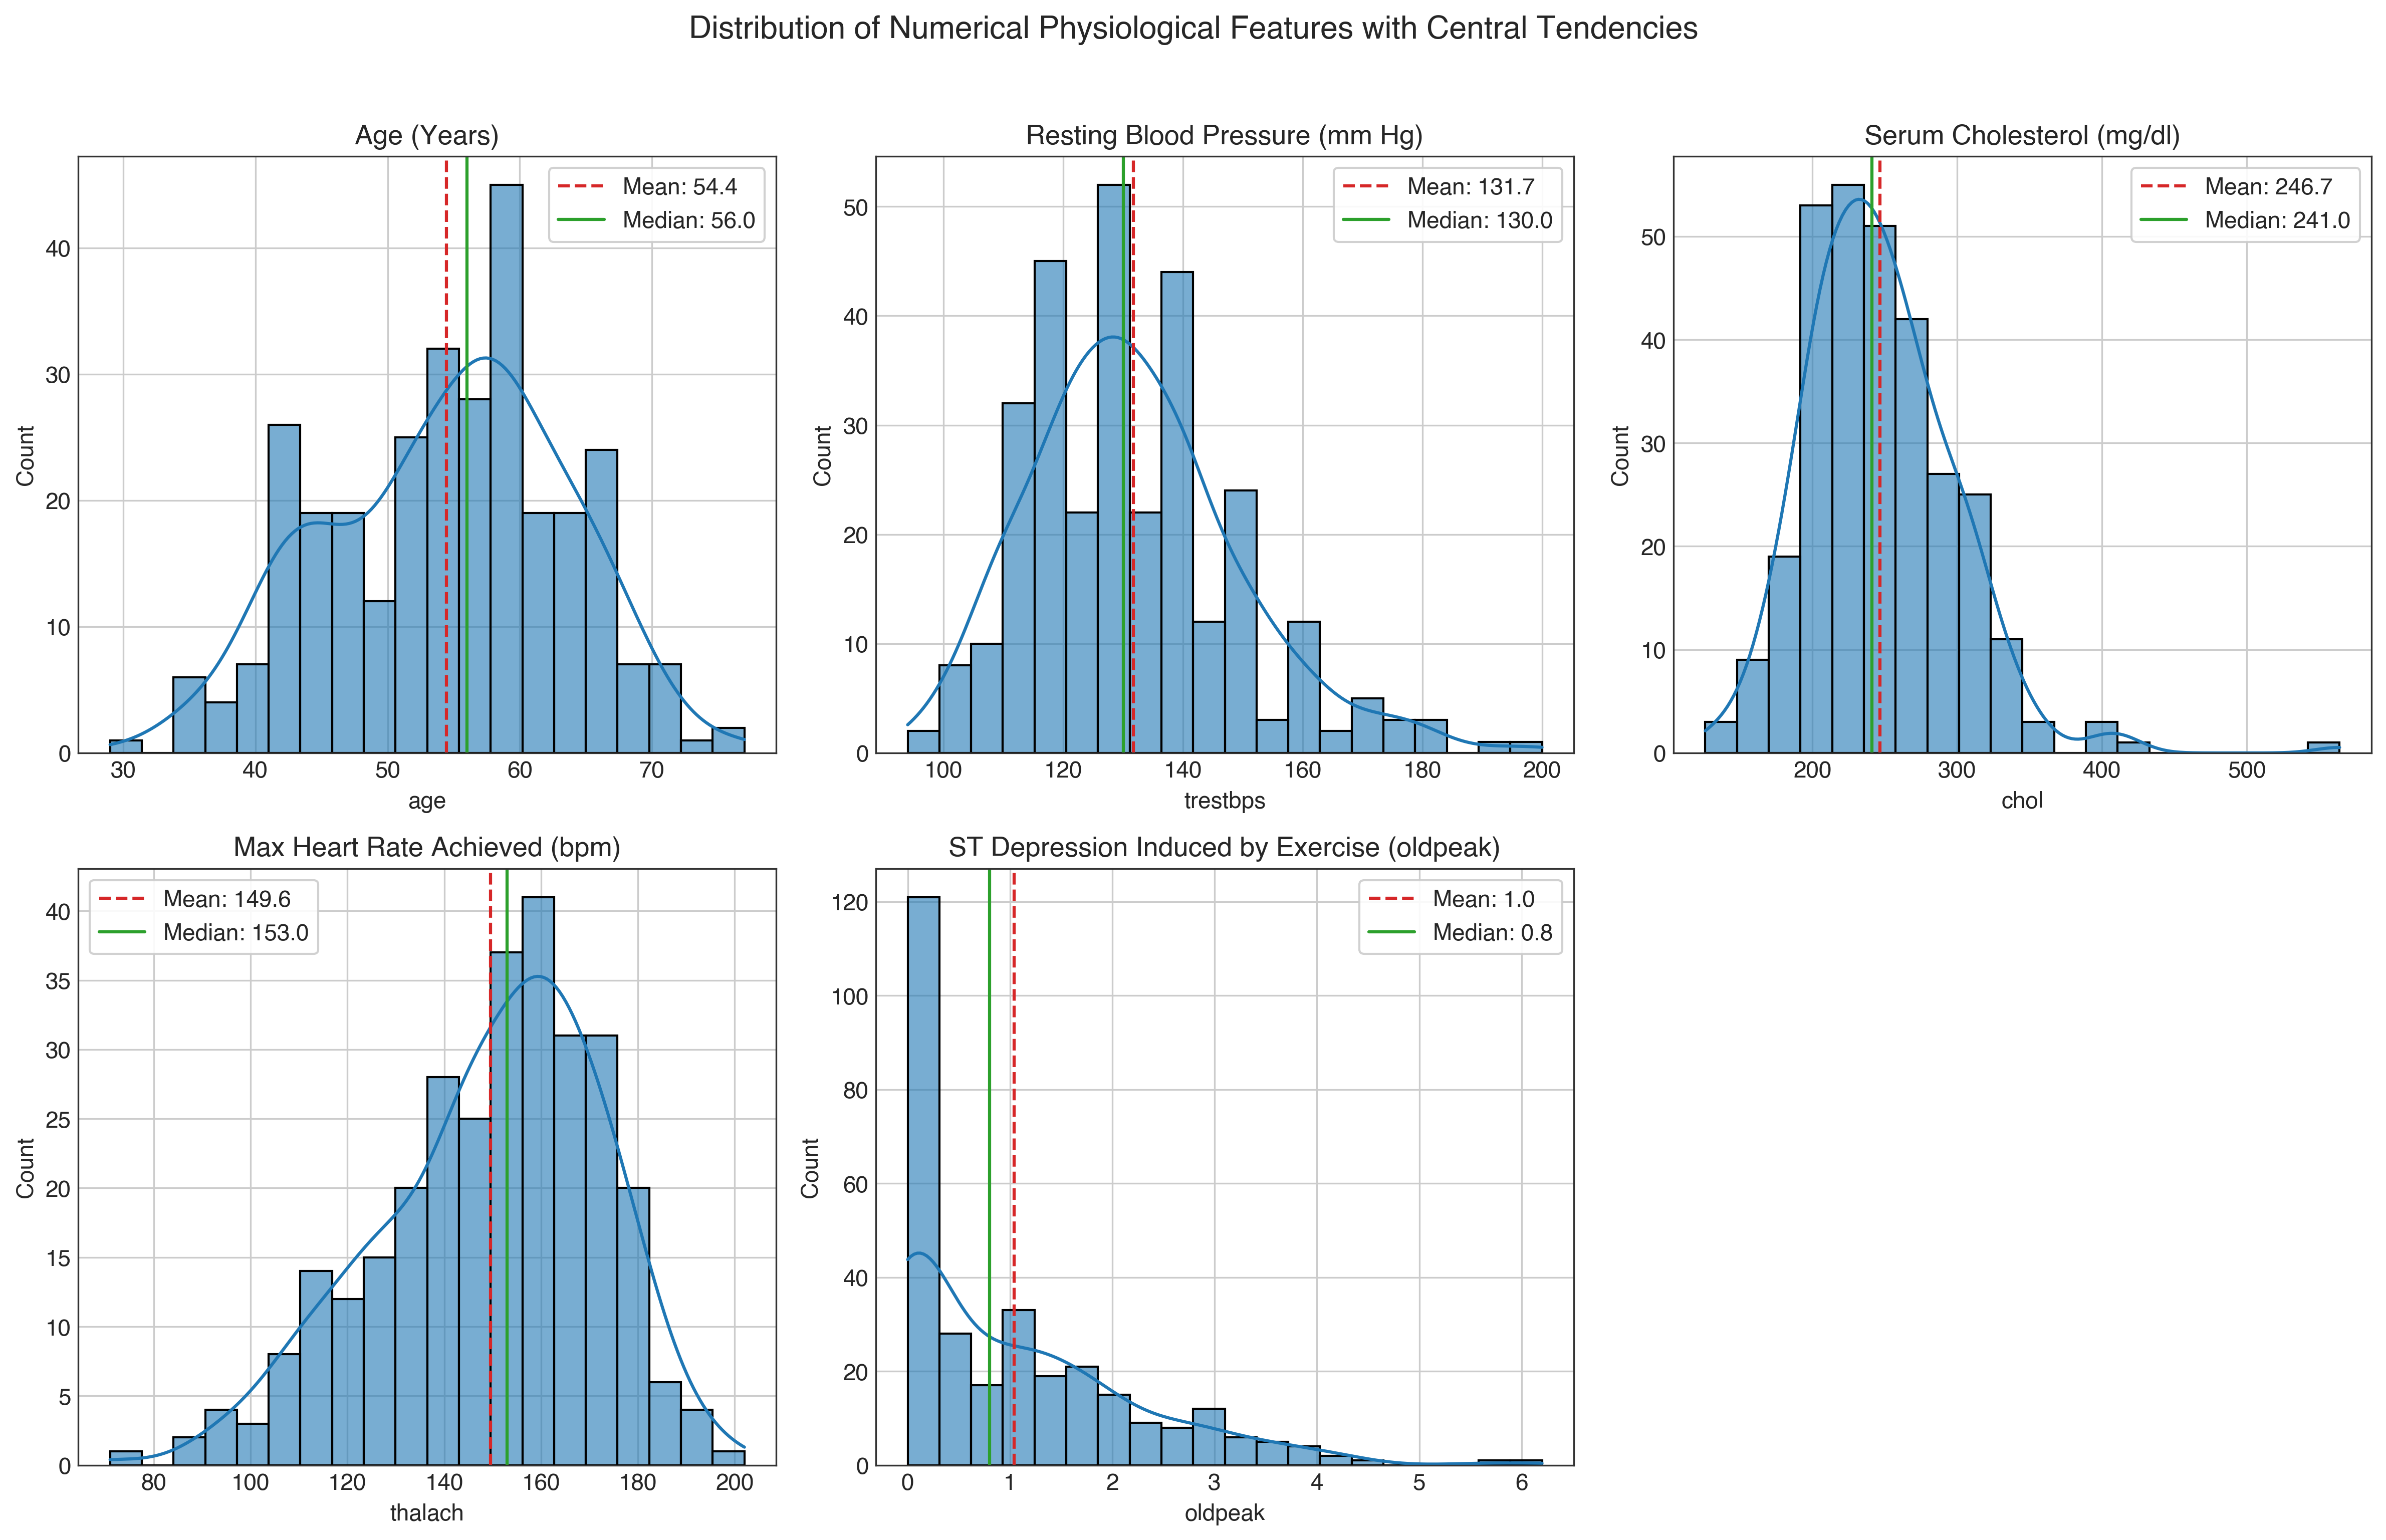

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.flatten()
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
titles = ['Age (Years)', 'Resting Blood Pressure (mm Hg)', 'Serum Cholesterol (mg/dl)', 'Max Heart Rate (bpm)', 'ST Depression (oldpeak)']
for i, col in enumerate(num_cols):
    ax = axes_flat[i]
    sns.histplot(df[col], kde=True, ax=ax, color='#1f77b4', edgecolor='black', alpha=0.6, bins=20)
    ax.axvline(df[col].mean(), color='#d62728', linestyle='--', label=f"Mean: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color='#2ca02c', linestyle='-', label=f"Median: {df[col].median():.1f}")
    ax.set_title(titles[i])
    ax.legend()
fig.delaxes(axes_flat[5])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numerical_histograms.png", dpi=300, bbox_inches='tight')
plt.show()

## 7. Categorical and Binary Feature Profiles

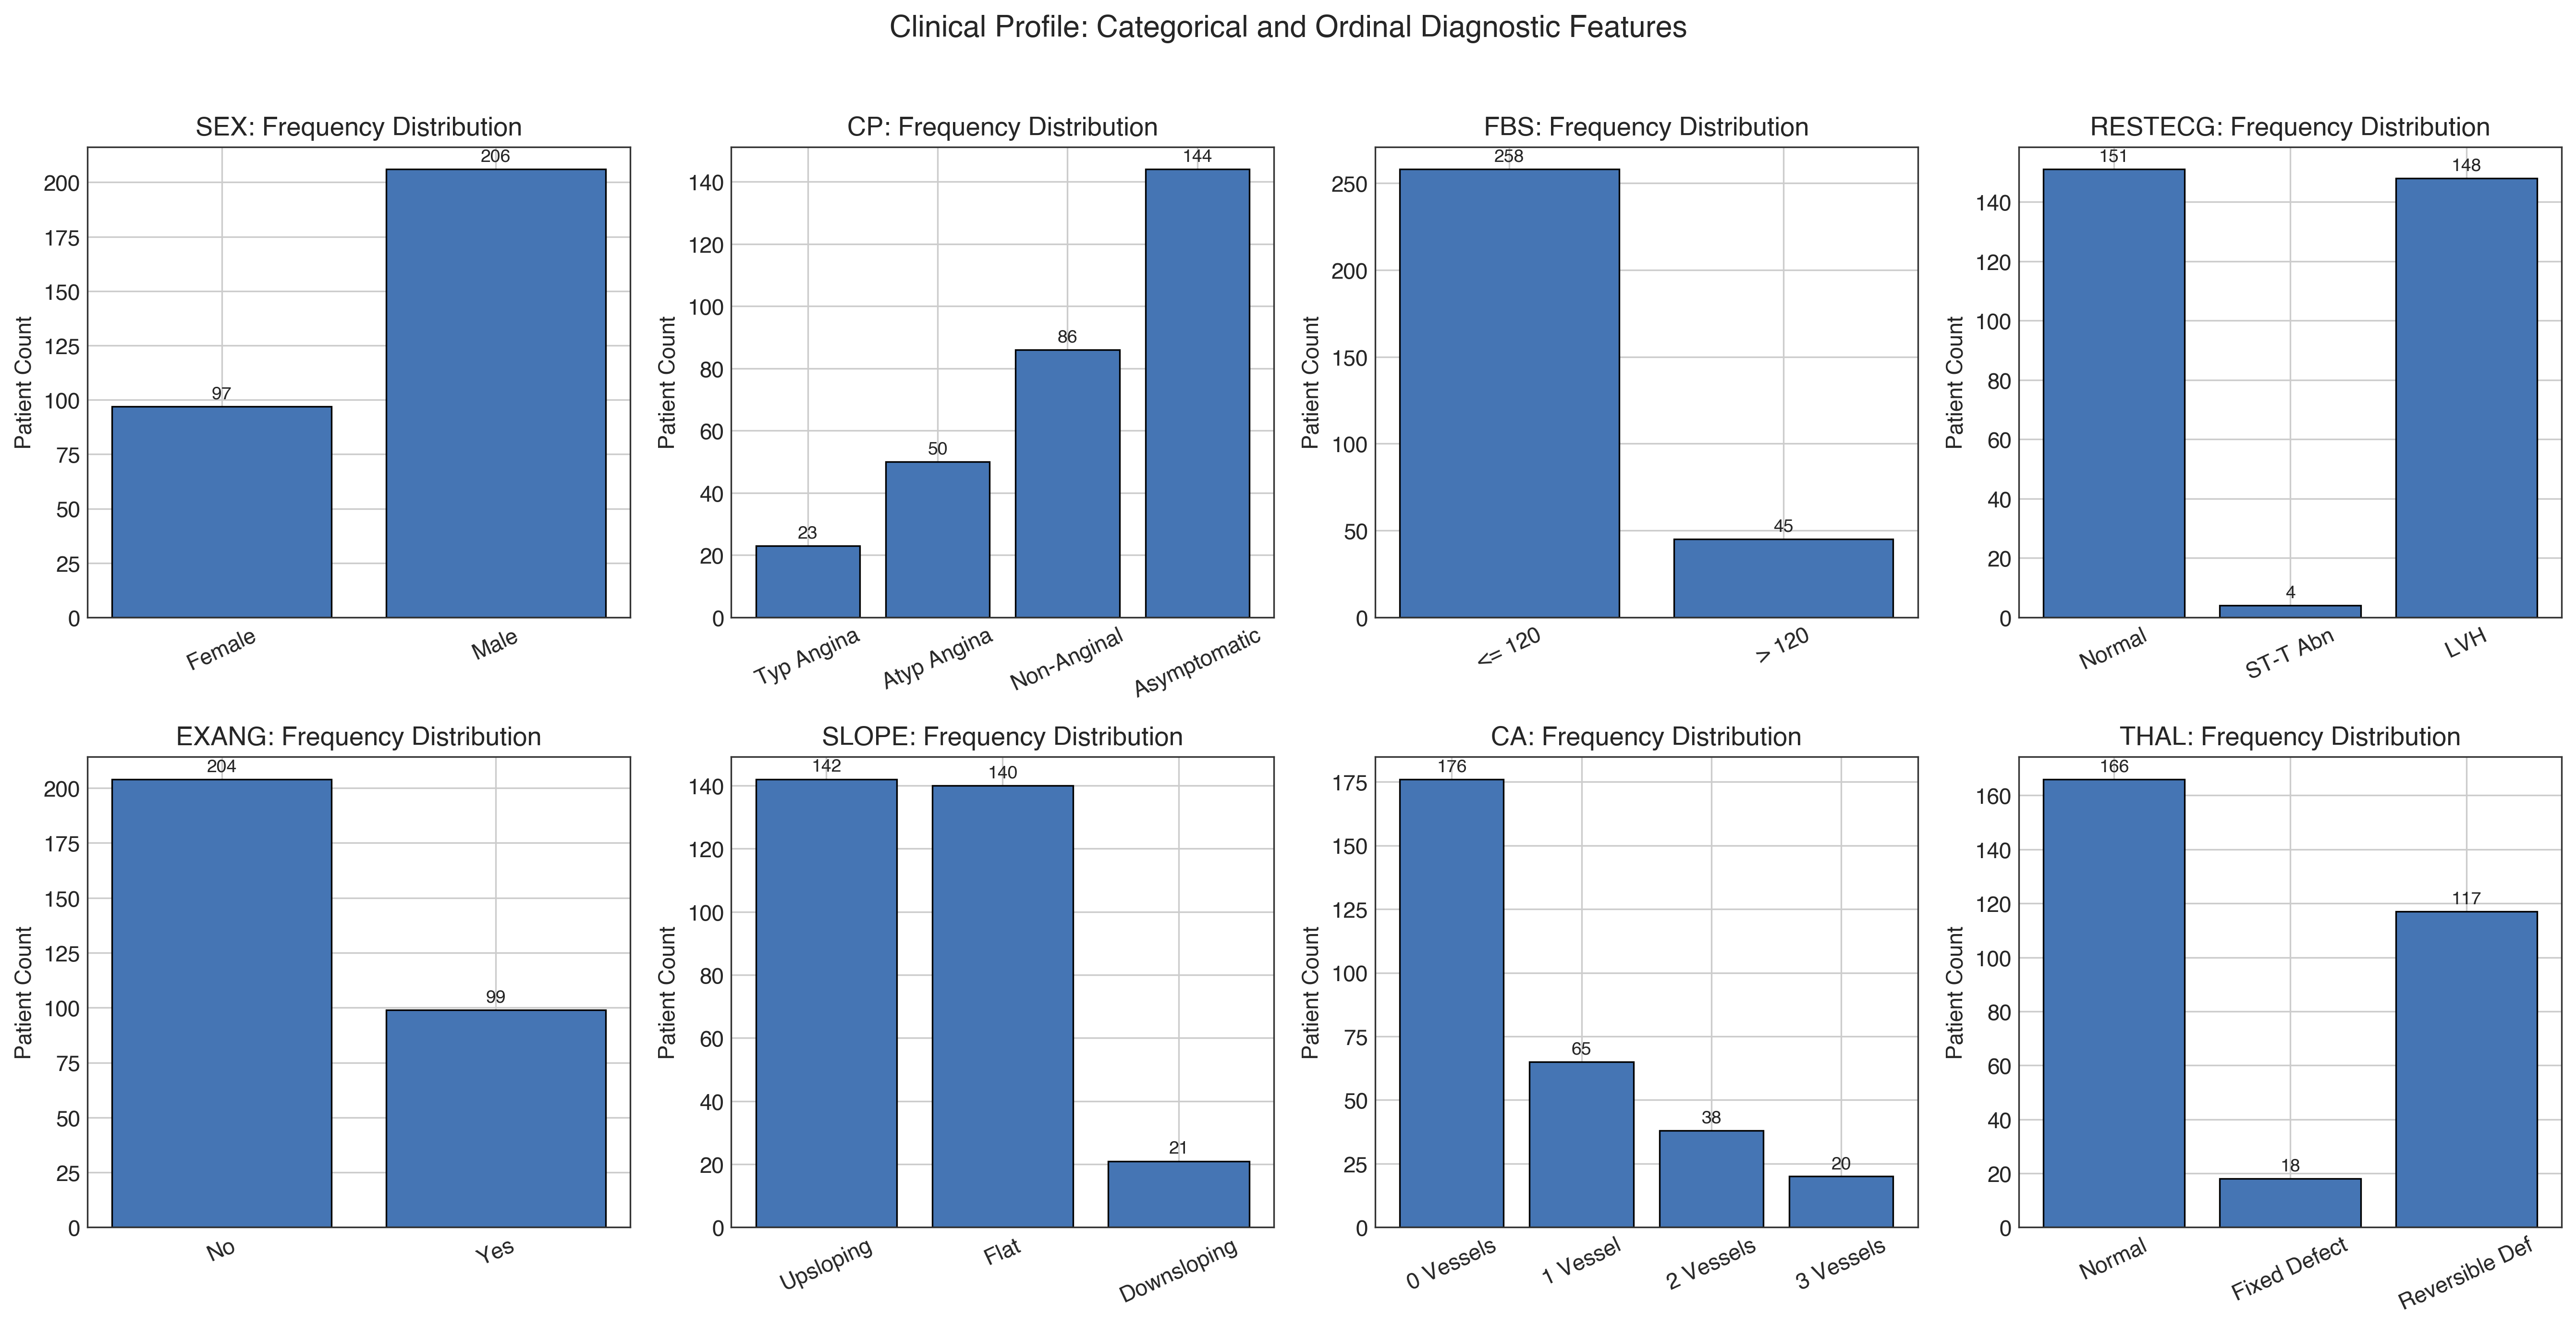

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes_flat = axes.flatten()
for i, col in enumerate(cat_features):
    ax = axes_flat[i]
    vc = df[col].value_counts().sort_index()
    ax.bar([str(v) for v in vc.index], vc.values, color='#4575b4', edgecolor='black')
    ax.set_title(col.upper())
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_categorical_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

## 8. Spearman Rank Correlation Heatmap

Spearman rank correlation evaluates monotonic relationships without assuming linear Gaussian bivariate normality.


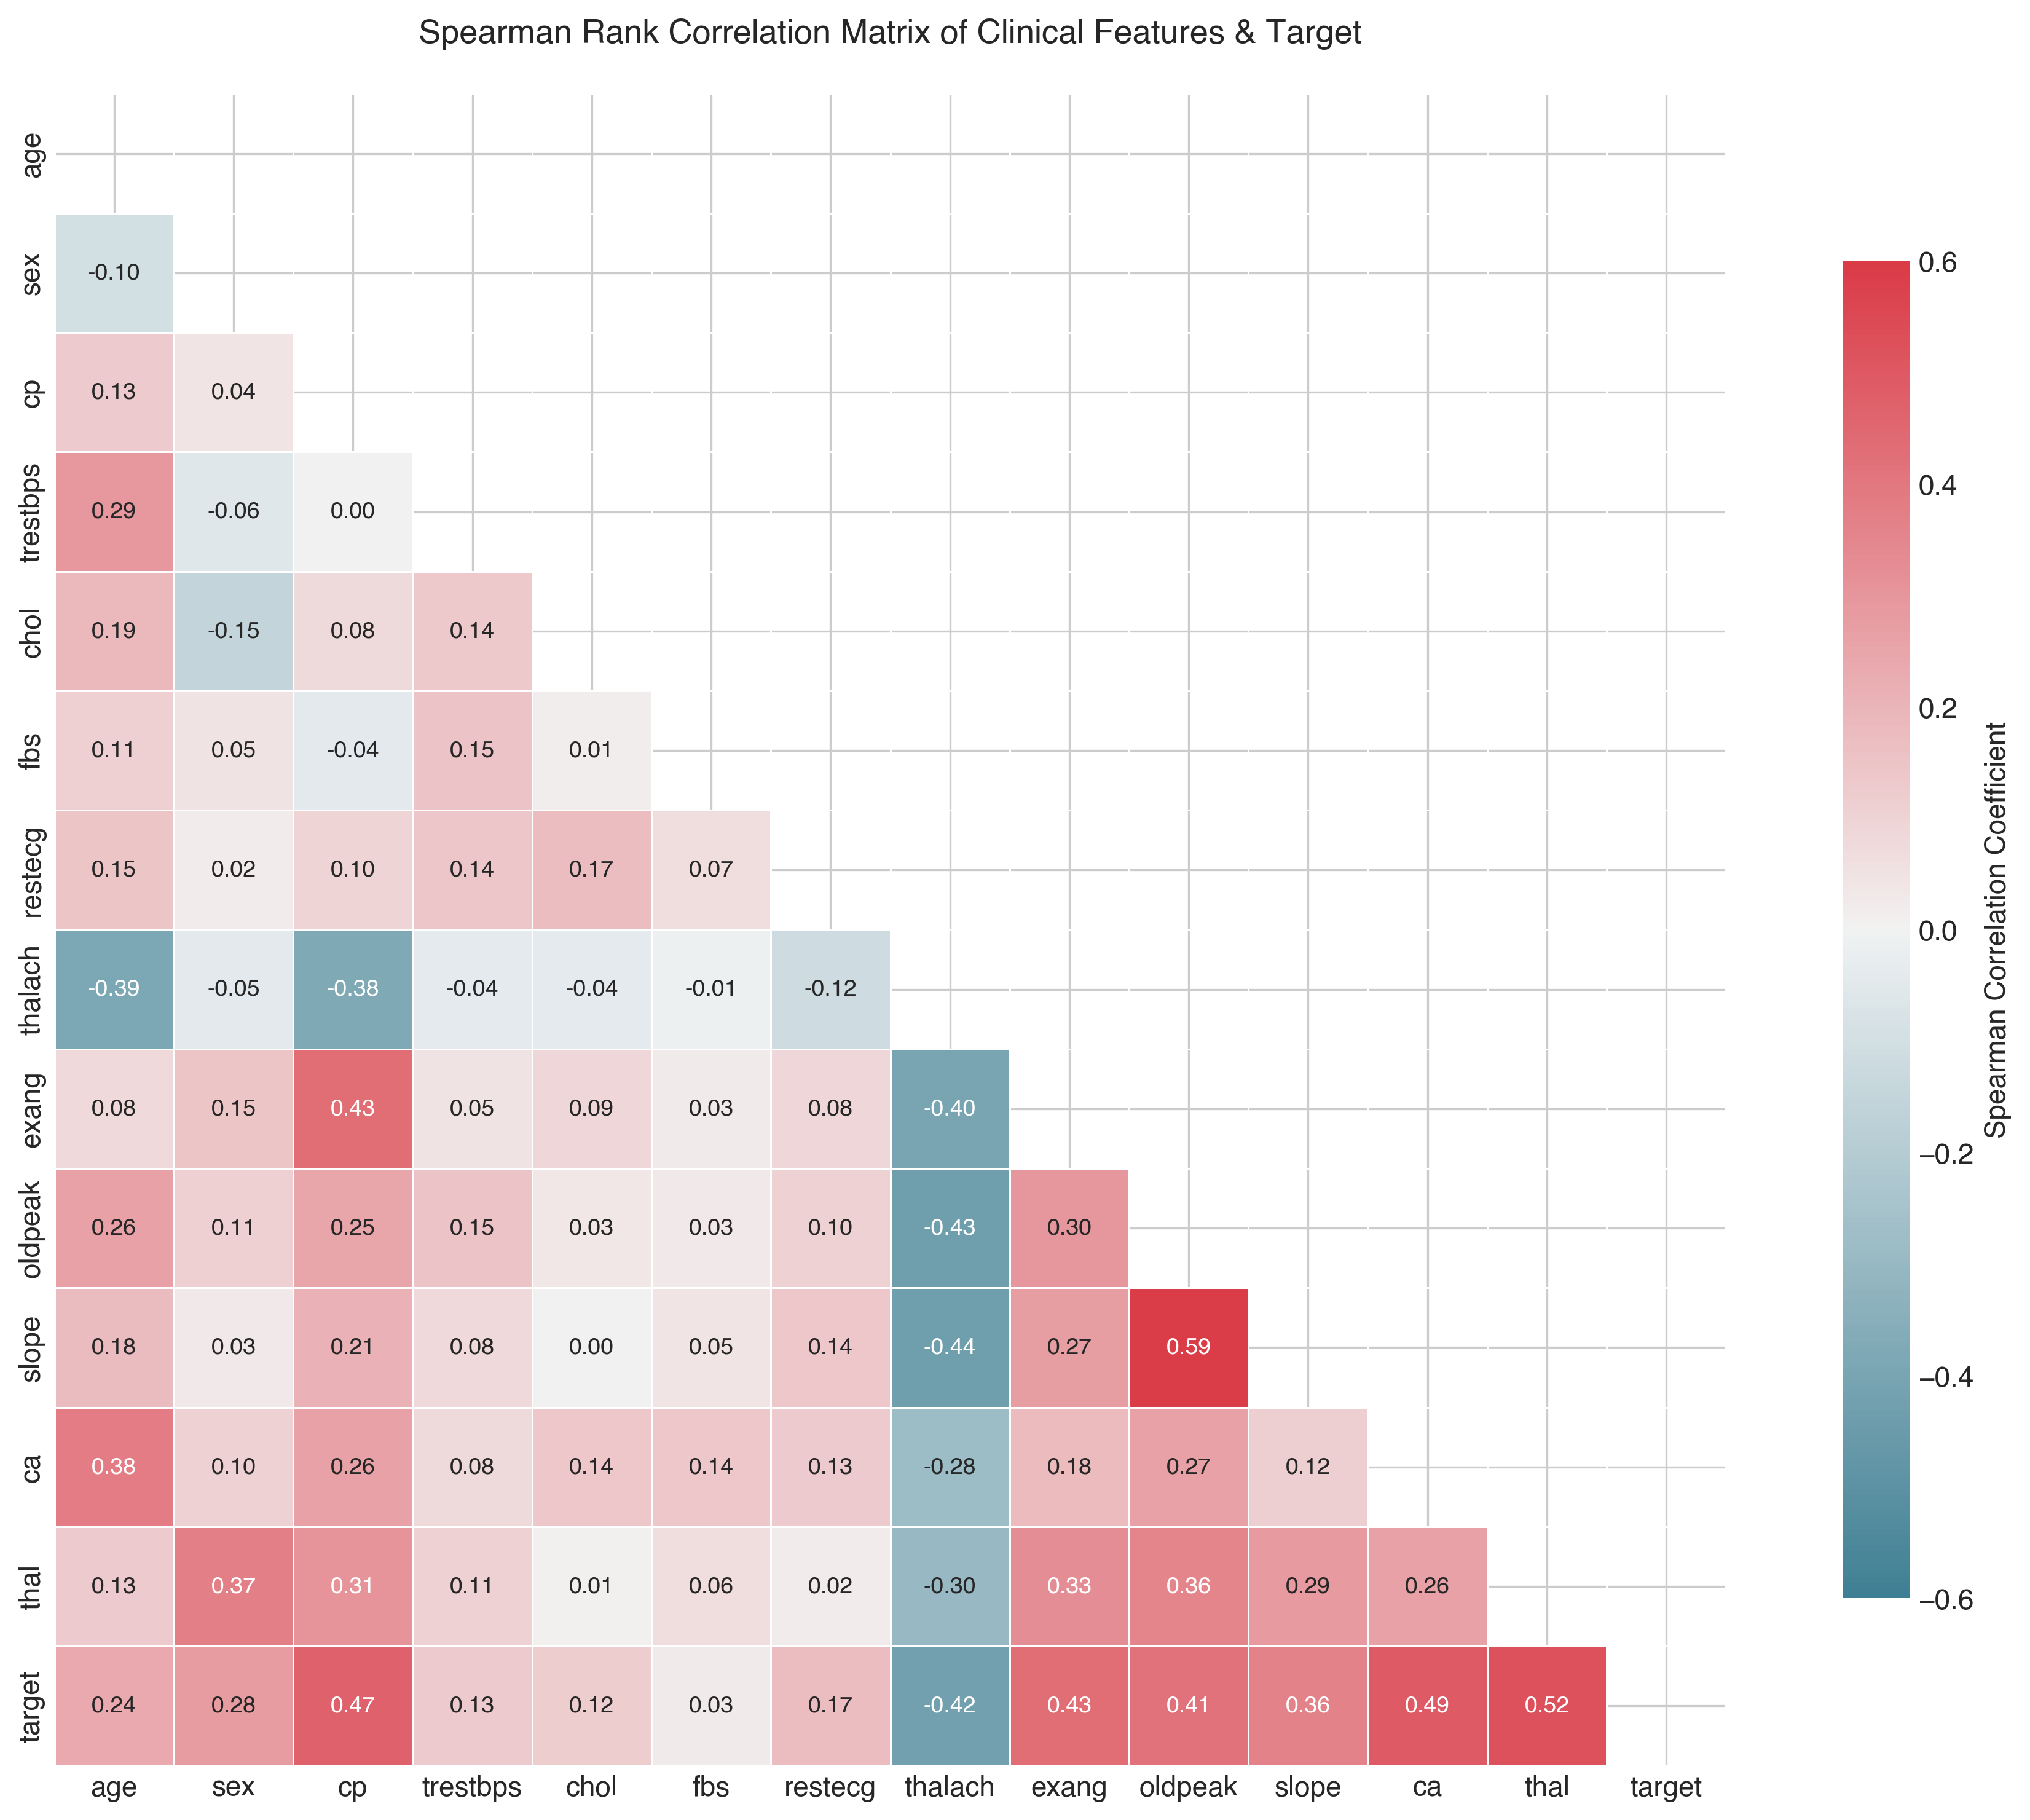

In [8]:
plt.figure(figsize=(13, 10))
corr_cols = [c for c in df.columns if c != 'target_raw']
corr_matrix = df[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, annot=True, fmt='.2f', square=True)
plt.title("Spearman Rank Correlation Matrix", pad=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

## 9. Biomarker Stratification: Continuous Features vs. Target

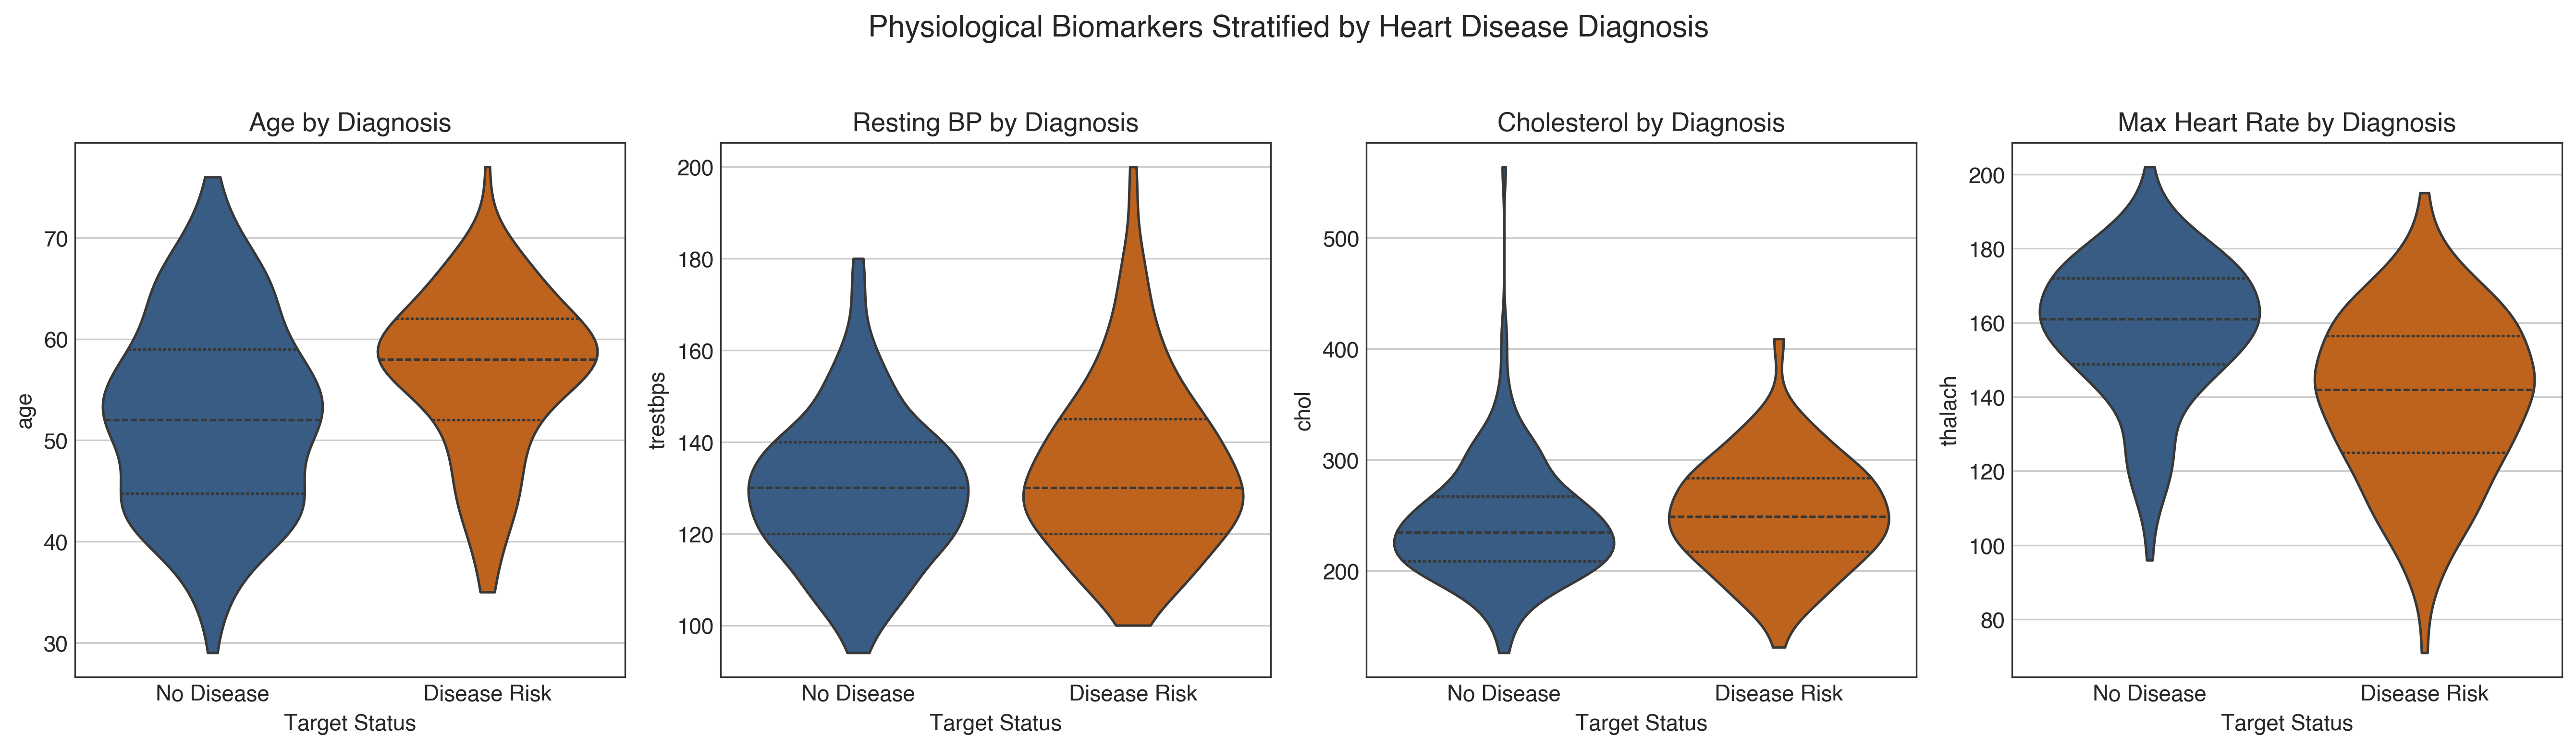

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
violin_features = ['age', 'trestbps', 'chol', 'thalach']
for i, col in enumerate(violin_features):
    ax = axes[i]
    sns.violinplot(x='target', y=col, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], inner='quartile')
    ax.set_xticklabels(['No Disease', 'Disease Risk'])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_feature_vs_target_violin.png", dpi=300, bbox_inches='tight')
plt.show()

## 10. Chest Pain Symptom Paradox vs. Angiographic Disease

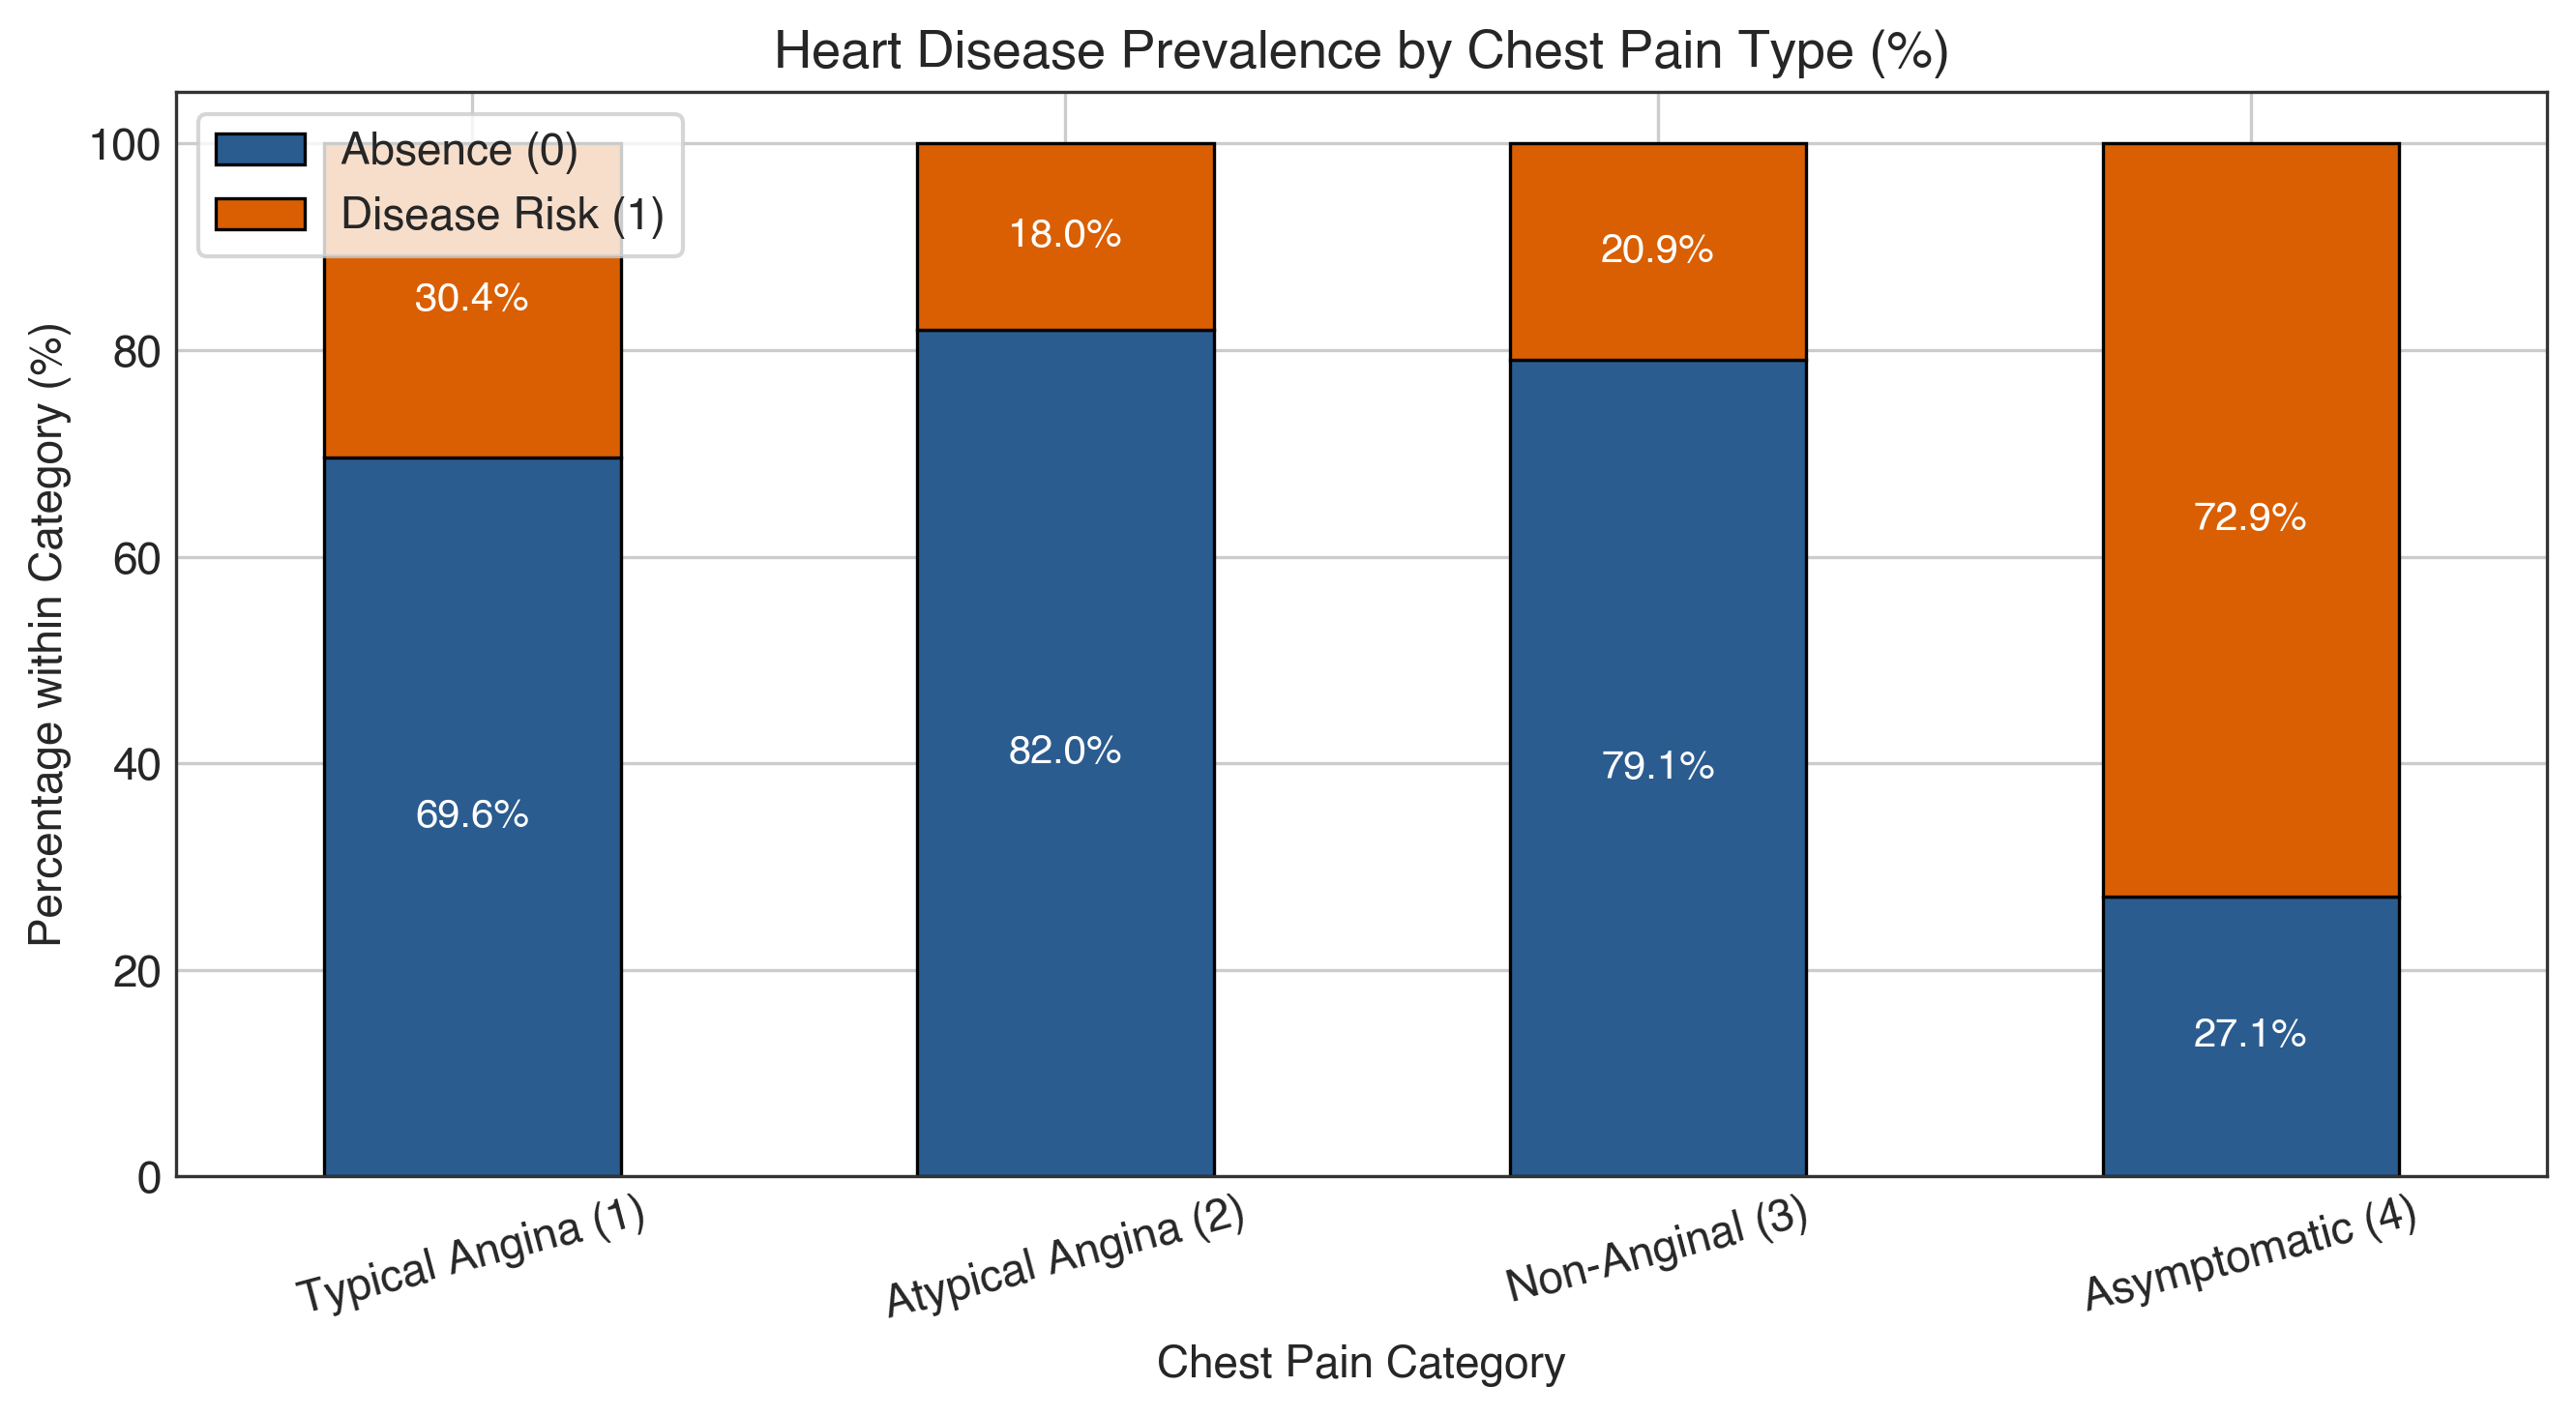

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
cp_ct = pd.crosstab(df['cp'], df['target'], normalize='index') * 100
cp_ct.index = ['Typical Angina (1)', 'Atypical Angina (2)', 'Non-Anginal (3)', 'Asymptomatic (4)']
cp_ct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=ax, edgecolor='black')
plt.title("Heart Disease Prevalence by Chest Pain Type (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_chest_pain_vs_disease.png", dpi=300, bbox_inches='tight')
plt.show()

## 11. Cardiovascular Capacity: Peak Heart Rate (thalach) vs. Patient Age

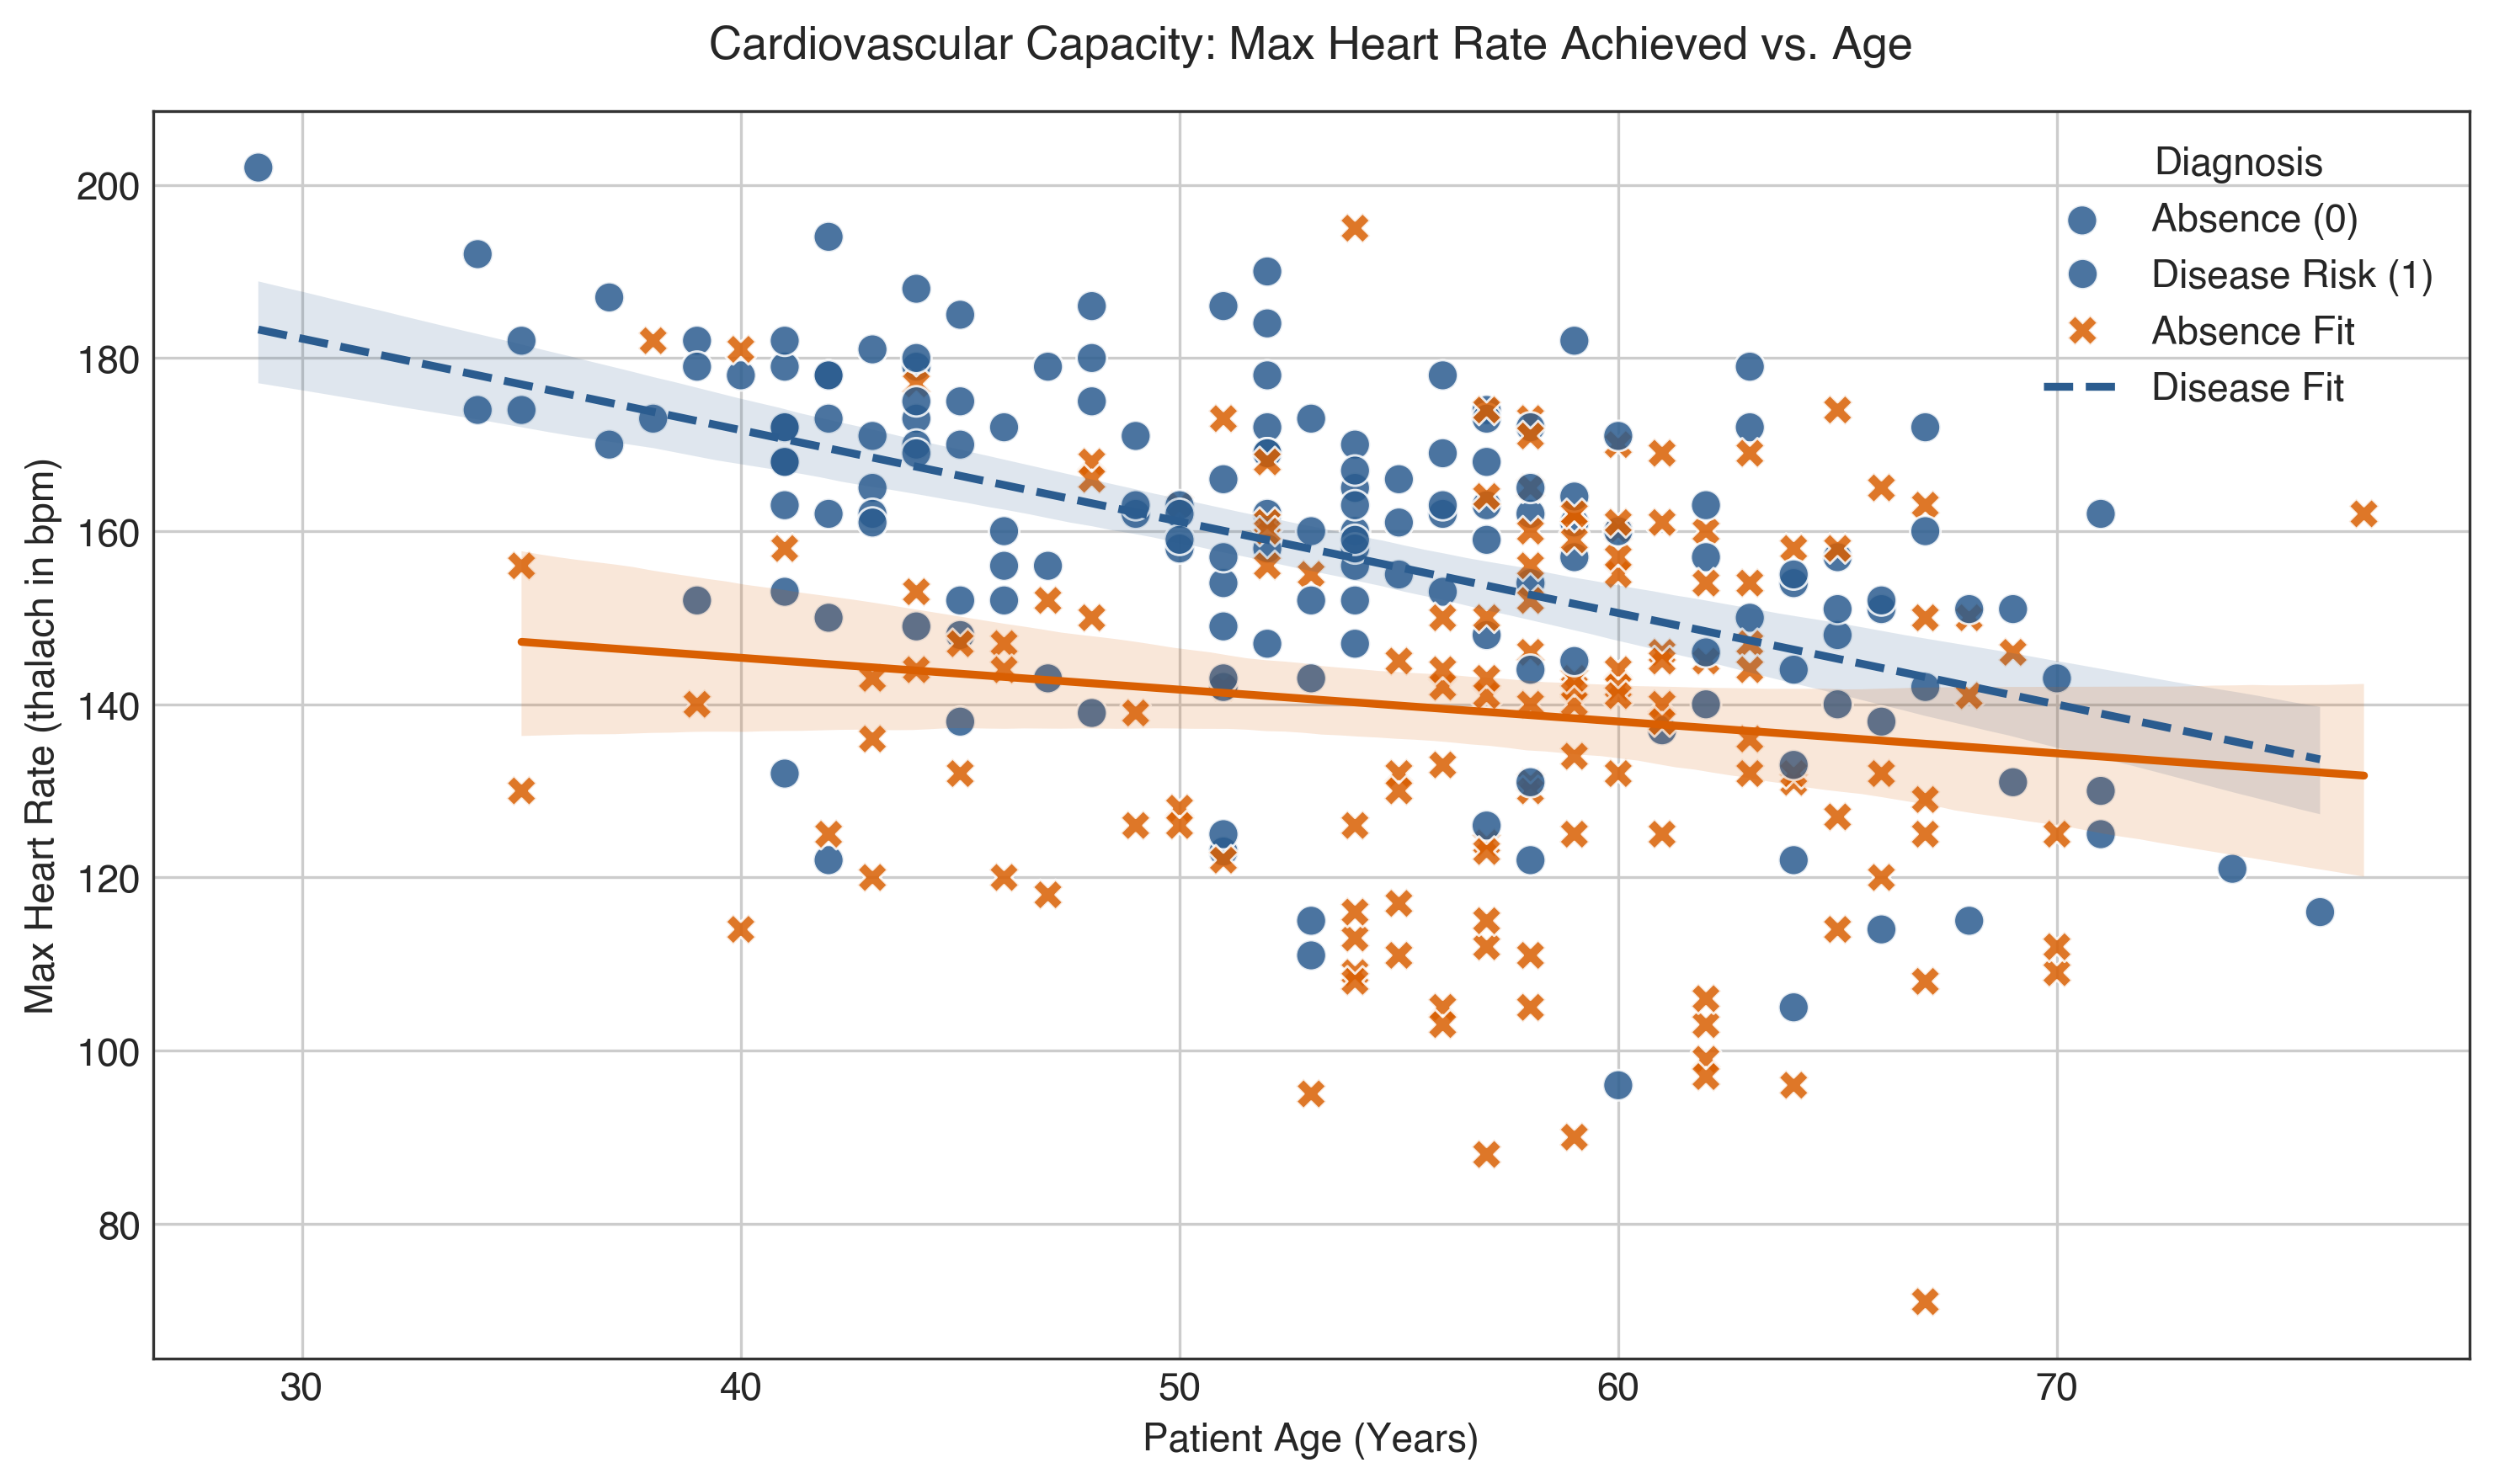

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='thalach', hue='target', palette=['#2b5c8f', '#d95f02'], data=df)
sns.regplot(x='age', y='thalach', data=df[df['target'] == 0], scatter=False, color='#2b5c8f')
sns.regplot(x='age', y='thalach', data=df[df['target'] == 1], scatter=False, color='#d95f02')
plt.title("Max Heart Rate vs Age with Diagnostic Trajectory")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_thalach_vs_age_scatter.png", dpi=300, bbox_inches='tight')
plt.show()

## 12. Objective Angiographic Indicators: Vessel Fluoroscopy & Scintigraphy

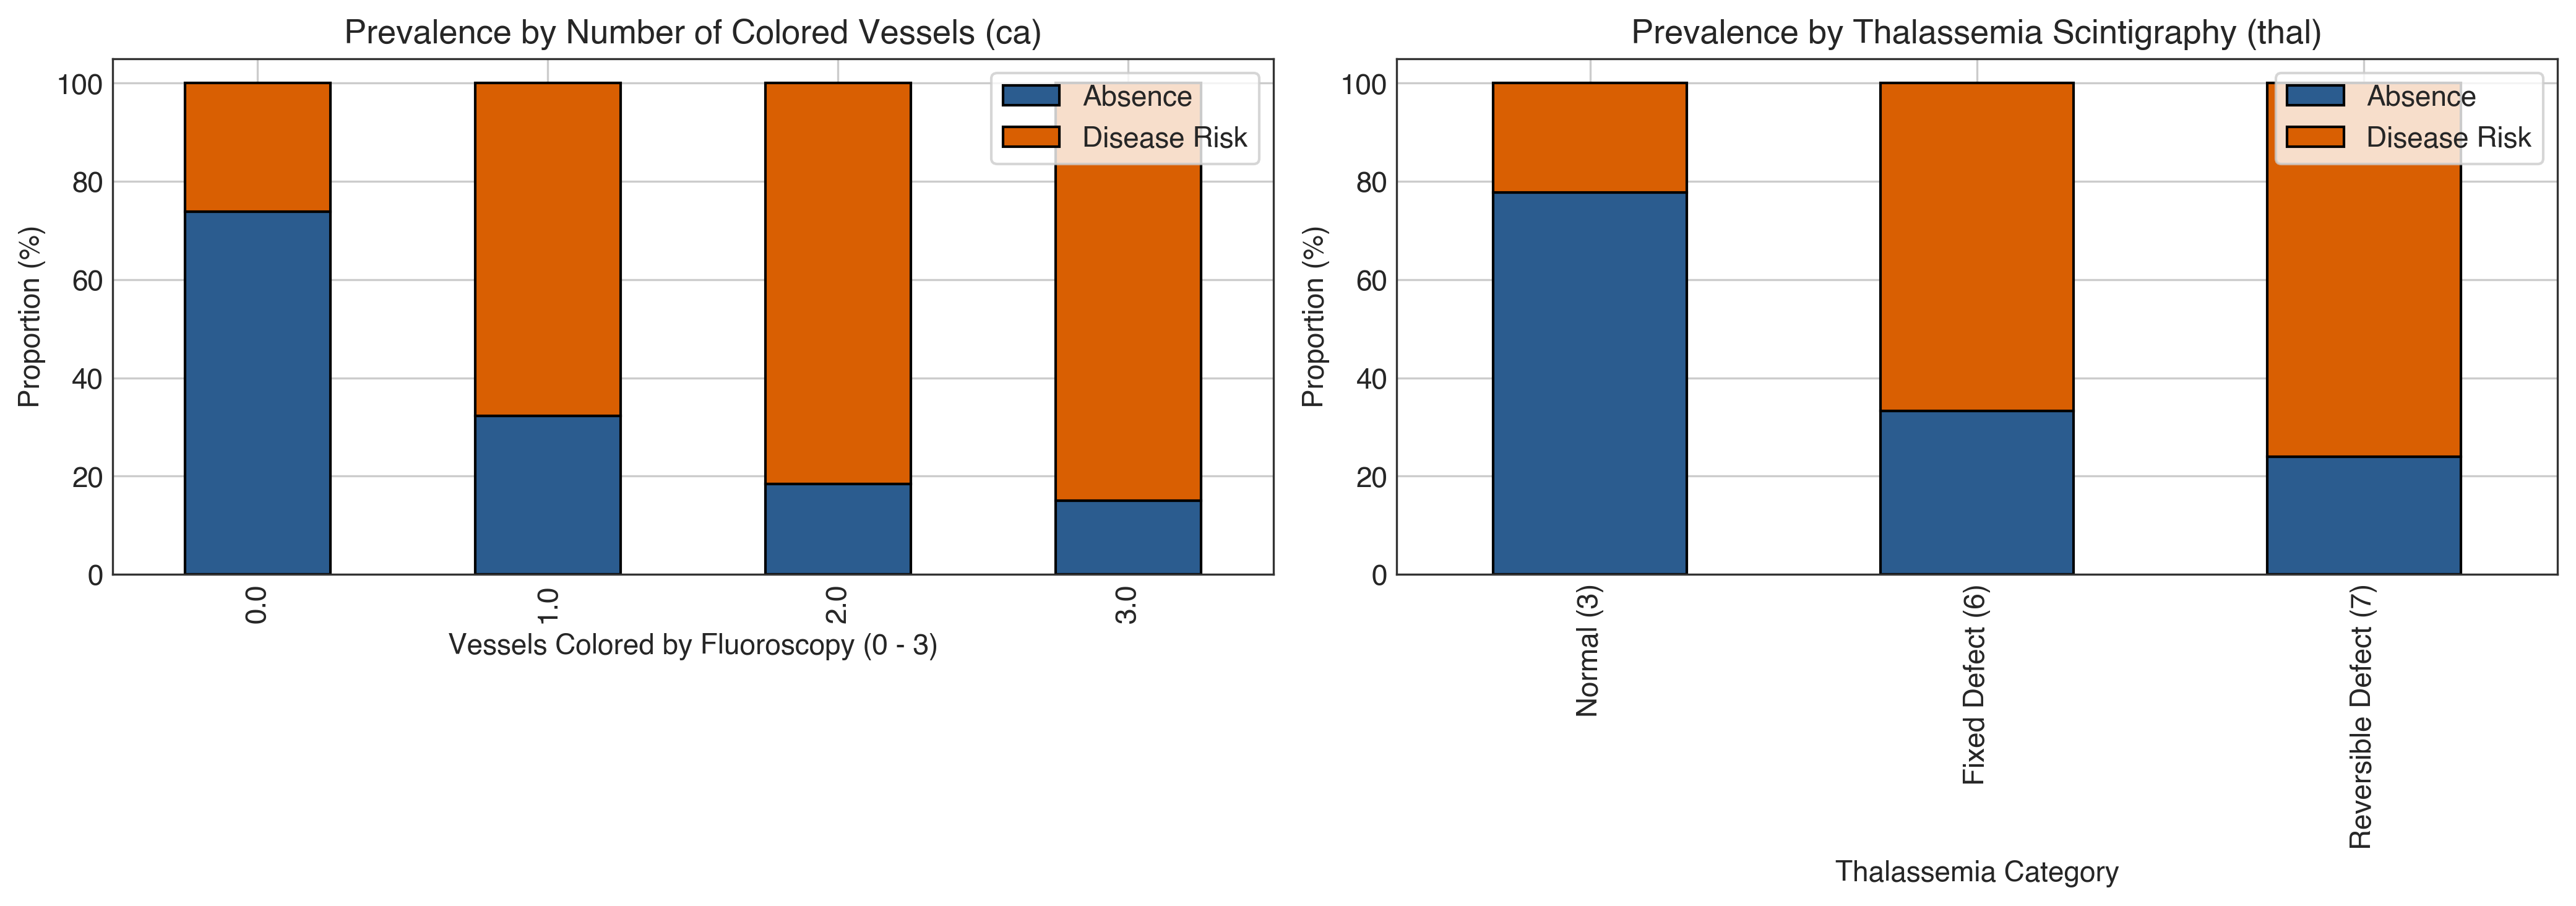

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ca_ct = pd.crosstab(df['ca'], df['target'], normalize='index') * 100
ca_ct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[0], edgecolor='black')
thal_ct = pd.crosstab(df['thal'], df['target'], normalize='index') * 100
thal_ct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[1], edgecolor='black')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_fluoroscopy_vessels_vs_target.png", dpi=300, bbox_inches='tight')
plt.show()

## 13. Clinical Insights, Observations, and Modeling Recommendations

### Key Empirical Findings:
1. **Target Balance:** The binary formulation yields 164 absence cases (54.1%) and 139 disease presence cases (45.9%). The balanced class distribution allows training without requiring synthetic oversampling techniques (e.g., SMOTE) while maintaining high statistical power.
2. **Stress Chronotropic Competence (`thalach`):** Patients exhibiting heart disease reach substantially lower peak heart rates ($\mu pprox 139$ bpm vs $\mu pprox 158$ bpm for healthy subjects, Spearman $ho = -0.42$).
3. **Exercise Ischemia (`oldpeak`):** ST segment depression $> 1.0$ mm strongly correlates with disease presence ($ho = +0.42$), serving as one of the most reliable non-invasive indicators.
4. **Angina Paradox (`cp`):** Asymptomatic chest pain (category 4) is counter-intuitively associated with the highest rate of angiographic disease (>70%), reflecting clinical referral bias where asymptomatic patients undergo angiography only when objective non-invasive testing reveals severe silent ischemia.
5. **Major Vessels (`ca`) and Thalassemia Defect (`thal`):** Fluoroscopy showing $\ge 1$ vessels or scintigraphy demonstrating reversible ischemia defects correlates with $>75\%$ disease prevalence.

### Feature Pipeline Strategy:
- **Zero-Leakage Imputation:** Numerical features imputed with median, categorical features imputed with mode inside each CV fold.
- **Scaling:** Continuous variables (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) standardized with `StandardScaler`.
- **Nominal Encoding:** One-hot encoding applied to `cp`, `restecg`, `slope`, `ca`, and `thal`.
- **Model Evaluation Metric:** In a clinical screening tool, **Recall** (Sensitivity) is paramount to minimize False Negatives (undiagnosed patients). We evaluate Recall alongside ROC-AUC, Precision, and Accuracy.
